# AirGuard: Explainable Air-Pollution Classification

**Objective:** Build and compare two machine learning models to classify observed carbon monoxide (CO) concentration into lower, moderate, and higher relative categories.

**Dataset:** UCI Air Quality Dataset

**Models:** Decision Tree and K-Nearest Neighbors (KNN)

## 1. Import Libraries

Import the Python libraries required for data manipulation, visualization, preprocessing, model training, and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("AirGuard project initialized!")

AirGuard project initialized!


## 2. Load the Dataset

Download the UCI Air Quality dataset and load it into a pandas DataFrame. Inspect its dimensions, sample records, and column data types.

In [2]:
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

response = requests.get(url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    csv_file = next(
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    )

    with archive.open(csv_file) as file:
        df = pd.read_csv(
            file,
            sep=";",
            decimal=",",
            na_values=[-200, "-200"]
        )

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)

Dataset shape: (9471, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


Date              object
Time              object
CO(GT)           float64
PT08.S1(CO)      float64
NMHC(GT)         float64
C6H6(GT)         float64
PT08.S2(NMHC)    float64
NOx(GT)          float64
PT08.S3(NOx)     float64
NO2(GT)          float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
T                float64
RH               float64
AH               float64
dtype: object


## 3. Data Cleaning and Missing-Value Analysis

Identify missing measurements and inspect their distribution across columns. The dataset uses -200 as a missing-value marker.

In [3]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDataset information:")
df.info()

Missing values per column:
NMHC(GT)         8557
CO(GT)           1797
NO2(GT)          1756
NOx(GT)          1753
PT08.S2(NMHC)     480
C6H6(GT)          480
PT08.S1(CO)       480
PT08.S5(O3)       480
T                 480
PT08.S3(NOx)      480
PT08.S4(NO2)      480
RH                480
AH                480
Date              114
Time              114
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         7674 non-null   float64
 3   PT08.S1(CO)    8991 non-null   float64
 4   NMHC(GT)       914 non-null    float64
 5   C6H6(GT)       8991 non-null   float64
 6   PT08.S2(NMHC)  8991 non-null   float64
 7   NOx(GT)        7718 non-null   float64
 8   PT08.S3(NOx)   8991 non-null   float64
 9   NO2(GT)     

## 4. Feature Preparation and Target Definition

Define the target classes from observed CO concentrations and select the input features. The classes represent relative concentration categories, not official AQI levels.

In [4]:
target_column = "CO(GT)"

# Keep rows with a valid target
df = df.dropna(subset=[target_column]).copy()

# Create three classes based on the observed CO distribution
df["CO_Class"] = pd.qcut(
    df[target_column],
    q=3,
    labels=["Lower", "Moderate", "Higher"],
    duplicates="drop"
)

# Remove the target measurement and timestamp from the inputs
X = df.drop(
    columns=["CO_Class", target_column, "Date", "Time"],
    errors="ignore"
)

# Keep numeric sensor and environmental features
X = X.select_dtypes(include=np.number)

y = df["CO_Class"]

print("Feature shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts())

display(X.head())

Feature shape: (7674, 12)

Class distribution:
CO_Class
Lower       2623
Higher      2545
Moderate    2506
Name: count, dtype: int64


,PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## 5. Split the Dataset

Divide the prepared dataset into training and testing subsets. Use a fixed random seed to make the experiment reproducible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 6139
Testing samples: 1535


## 6. Model Building

Train two classification models: Decision Tree and K-Nearest Neighbors (KNN). Apply suitable missing-value handling and feature scaling for KNN.

In [6]:
models = {
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=6,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred
    results[name] = accuracy_score(y_test, y_pred)

    print(f"{name} accuracy: {results[name]:.3f}")

Decision Tree accuracy: 0.842
KNN accuracy: 0.861


## 7. Model Evaluation and Comparison

Compare both models using test-set accuracy, classification reports, and confusion matrices. Examine errors across the three classes rather than relying on accuracy alone.

,Model,Accuracy
1,KNN,0.861238
0,Decision Tree,0.842345



Decision Tree
              precision    recall  f1-score   support

      Higher       0.92      0.87      0.89       509
       Lower       0.89      0.83      0.86       525
    Moderate       0.74      0.82      0.78       501

    accuracy                           0.84      1535
   macro avg       0.85      0.84      0.84      1535
weighted avg       0.85      0.84      0.84      1535



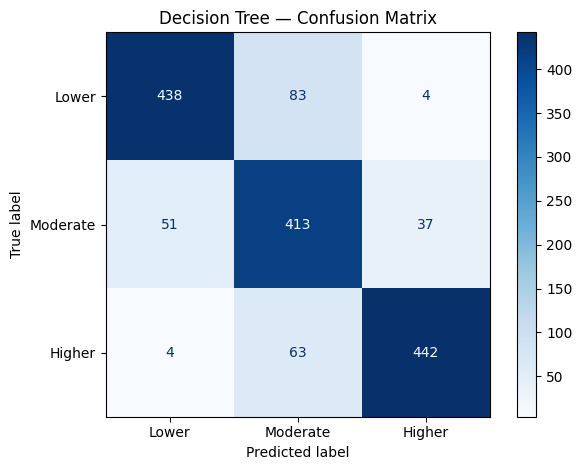


KNN
              precision    recall  f1-score   support

      Higher       0.89      0.89      0.89       509
       Lower       0.91      0.87      0.89       525
    Moderate       0.79      0.82      0.80       501

    accuracy                           0.86      1535
   macro avg       0.86      0.86      0.86      1535
weighted avg       0.86      0.86      0.86      1535



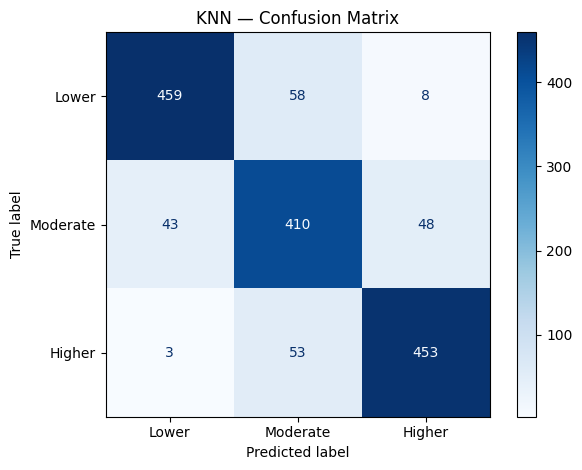

In [7]:
results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": list(results.values())
}).sort_values("Accuracy", ascending=False)

display(results_df)

for name, y_pred in predictions.items():
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Lower", "Moderate", "Higher"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

## 8. Feature Importance and Interpretation

Inspect the Decision Tree's feature-importance scores to identify which sensor measurements contributed most to its predictions. Feature importance does not establish causation.

Top 5 features:


,0
PT08.S2(NMHC),0.724827
NOx(GT),0.164140
PT08.S1(CO),0.026114
NO2(GT),0.022527
NMHC(GT),0.015611


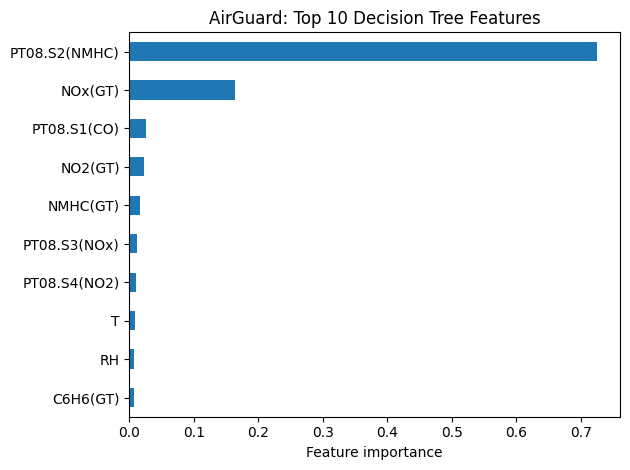

In [8]:
tree_model = models["Decision Tree"].named_steps["model"]

importance = pd.Series(
    tree_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 5 features:")
display(importance.head(5))

importance.head(10).sort_values().plot(kind="barh")
plt.title("AirGuard: Top 10 Decision Tree Features")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

## 9. Conclusion and Future Improvements

Summarize the model comparison, discuss important features and classification errors, acknowledge limitations, and identify possible improvements.